In [21]:
!pip -q install kaggle

In [22]:
import os
import random
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms as transforms
from torchvision.utils import make_grid

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# For reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

PyTorch version: 2.10.0+cu128
CUDA available: True
Using device: cuda


In [23]:
from google.colab import files
import shutil

uploaded = files.upload()

# Colab may rename the file to "kaggle (1).json", "kaggle (2).json", etc.
kaggle_json_candidates = [
    name for name in uploaded.keys()
    if name.lower().startswith("kaggle") and name.lower().endswith(".json")
]

if len(kaggle_json_candidates) == 0:
    raise FileNotFoundError(
        "Please upload your Kaggle API token file. It should be named kaggle.json "
        "or something like kaggle (1).json."
    )

kaggle_json_file = kaggle_json_candidates[0]
print("Using Kaggle token file:", kaggle_json_file)

Saving kaggle (2).json to kaggle (2) (1).json
Using Kaggle token file: kaggle (2) (1).json


In [24]:
KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy(kaggle_json_file, KAGGLE_DIR / "kaggle.json")
os.chmod(KAGGLE_DIR / "kaggle.json", 0o600)

print("Kaggle API token is ready.")

Kaggle API token is ready.


In [25]:
DATA_DIR = Path("/content/flowers_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download the dataset with Kaggle API.
# The command is safe to run again because Kaggle will simply download the zip file.
!kaggle datasets download -d alxmamaev/flowers-recognition -p /content/flowers_dataset

# Unzip automatically
zip_files = list(DATA_DIR.glob("*.zip"))
if len(zip_files) == 0:
    raise FileNotFoundError("No zip file was downloaded. Check Kaggle API setup.")

for z in zip_files:
    with zipfile.ZipFile(z, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("Dataset downloaded and extracted to:", DATA_DIR)

# Show the main folders so it is easy to check the extraction result
for folder in sorted([p for p in DATA_DIR.rglob("*") if p.is_dir()])[:15]:
    print(folder)

Dataset URL: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition
License(s): unknown
flowers-recognition.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset downloaded and extracted to: /content/flowers_dataset
/content/flowers_dataset/flowers
/content/flowers_dataset/flowers/daisy
/content/flowers_dataset/flowers/dandelion
/content/flowers_dataset/flowers/rose
/content/flowers_dataset/flowers/sunflower
/content/flowers_dataset/flowers/tulip


In [26]:
class ImageFolderNoLabels(Dataset):
    """Simple image dataset that loads image files recursively from one folder."""
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        extensions = ["*.jpg", "*.jpeg", "*.png"]
        self.image_paths = []
        for ext in extensions:
            self.image_paths.extend(list(self.root_dir.rglob(ext)))

        self.image_paths = sorted(self.image_paths)

        if len(self.image_paths) == 0:
            raise RuntimeError(f"No images found in {self.root_dir}. Check the dataset path.")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


image_size = 64
batch_size = 64
max_images = 900  # around 800-1000 images for faster Colab training
flower_class = "daisy"

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# The Kaggle zip usually extracts to flowers/daisy, but this search makes it more robust.
possible_class_dirs = [p for p in DATA_DIR.rglob(flower_class) if p.is_dir()]
if len(possible_class_dirs) == 0:
    raise FileNotFoundError(f"Could not find a folder named '{flower_class}' inside {DATA_DIR}")

class_dir = possible_class_dirs[0]
print("Using flower class folder:", class_dir)

dataset = ImageFolderNoLabels(class_dir, transform=transform)
print("Total daisy images found:", len(dataset))

# Use a limited random subset for quick training
subset_size = min(max_images, len(dataset))
indices = list(range(len(dataset)))
random.shuffle(indices)
train_dataset = Subset(dataset, indices[:subset_size])

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training images used:", len(train_dataset))

Using flower class folder: /content/flowers_dataset/flowers/daisy
Total daisy images found: 764
Training images used: 764


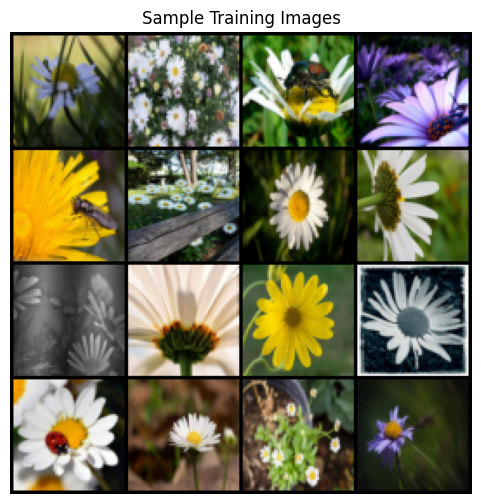

In [27]:
def denormalize(x):
    """Convert image tensor from [-1, 1] back to [0, 1] for plotting."""
    return (x * 0.5) + 0.5

images = next(iter(train_loader))[:16]
grid = make_grid(denormalize(images), nrow=4)

plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Sample Training Images")
plt.show()

In [28]:
LATENT_DIM = 256

class PatchEmbedding(nn.Module):
    """Turn an image into a sequence of patch embeddings."""
    def __init__(self, img_size=64, patch_size=8, in_channels=3, embed_dim=128):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2

        # Conv2d with stride=patch_size acts like splitting image into patches
        self.proj = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        # x shape: [batch, channels, height, width]
        x = self.proj(x)            # [batch, embed_dim, patches_h, patches_w]
        x = x.flatten(2)            # [batch, embed_dim, num_patches]
        x = x.transpose(1, 2)       # [batch, num_patches, embed_dim]
        return x


class ViTVAE(nn.Module):
    """A small ViT-style Variational Autoencoder for image generation."""
    def __init__(
        self,
        img_size=64,
        patch_size=8,
        in_channels=3,
        embed_dim=128,
        latent_dim=LATENT_DIM,
        num_heads=4,
        num_layers=4,
        ff_dim=512
    ):
        super().__init__()

        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # Learnable class token and positional embedding, similar to ViT
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))

        # Actual transformer encoder layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # VAE latent distribution
        self.fc_mu = nn.Linear(embed_dim, latent_dim)
        self.fc_logvar = nn.Linear(embed_dim, latent_dim)

        # Project latent vector to a small feature map for the decoder
        self.fc_decode = nn.Linear(latent_dim, 256 * 4 * 4)

        # Small CNN decoder to produce 64x64 RGB images
        # Final Tanh is used because images are normalized to [-1, 1].
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # 8x8
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # 32x32
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),    # 64x64
            nn.Tanh()
        )

        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.pos_embed, std=0.02)
        nn.init.normal_(self.cls_token, std=0.02)

    def encode(self, x):
        tokens = self.patch_embed(x)
        batch_size = tokens.size(0)

        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat([cls_tokens, tokens], dim=1)
        tokens = tokens + self.pos_embed

        encoded = self.transformer_encoder(tokens)

        # Use the class token as the global image representation
        cls_output = encoded[:, 0]
        mu = self.fc_mu(cls_output)
        logvar = self.fc_logvar(cls_output)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        # Reparameterization trick: z = mu + std * noise
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)
        return mu + noise * std

    def decode(self, z):
        x = self.fc_decode(z)
        x = x.view(z.size(0), 256, 4, 4)
        x = self.decoder(x)
        return x

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar


model = ViTVAE().to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {num_params:,}")

ViTVAE(
  (patch_embed): PatchEmbedding(
    (proj): Conv2d(3, 128, kernel_size=(8, 8), stride=(8, 8))
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (fc_mu): Linear(in_features=128, out_features=256, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=256, bias=True)
  (fc_decode): Linear(in_features=256, out_f

/tmp/ipykernel_3399/268818957.py:60: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(


In [29]:
def vae_loss(recon_x, x, mu, logvar, beta=0.0005):
    # L1 loss usually gives slightly sharper reconstructions than MSE for simple image work
    recon_loss = F.l1_loss(recon_x, x, reduction="mean")

    # KL divergence term for VAE
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())

    total_loss = recon_loss + beta * kl_loss
    return total_loss, recon_loss, kl_loss

In [30]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

epochs = 30
loss_history = []

criterion = nn.L1Loss()

model.train()

for epoch in range(epochs):

    total_loss_epoch = 0

    for batch in train_loader:

        batch = batch.to(device)

        optimizer.zero_grad()

        # model still returns (recon, mu, logvar)
        output = model(batch)

        # take reconstruction only
        recon = output[0]

        # reconstruction loss only
        loss = criterion(recon, batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss_epoch += loss.item()

    avg_loss = total_loss_epoch / len(train_loader)

    loss_history.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/30] Loss: 0.5724
Epoch [2/30] Loss: 0.4734
Epoch [3/30] Loss: 0.4261
Epoch [4/30] Loss: 0.3979
Epoch [5/30] Loss: 0.3827
Epoch [6/30] Loss: 0.3726
Epoch [7/30] Loss: 0.3659
Epoch [8/30] Loss: 0.3626
Epoch [9/30] Loss: 0.3580
Epoch [10/30] Loss: 0.3560
Epoch [11/30] Loss: 0.3518
Epoch [12/30] Loss: 0.3475
Epoch [13/30] Loss: 0.3412
Epoch [14/30] Loss: 0.3401
Epoch [15/30] Loss: 0.3392
Epoch [16/30] Loss: 0.3360
Epoch [17/30] Loss: 0.3326
Epoch [18/30] Loss: 0.3313
Epoch [19/30] Loss: 0.3303
Epoch [20/30] Loss: 0.3276
Epoch [21/30] Loss: 0.3230
Epoch [22/30] Loss: 0.3213
Epoch [23/30] Loss: 0.3222
Epoch [24/30] Loss: 0.3231
Epoch [25/30] Loss: 0.3182
Epoch [26/30] Loss: 0.3159
Epoch [27/30] Loss: 0.3143
Epoch [28/30] Loss: 0.3122
Epoch [29/30] Loss: 0.3128
Epoch [30/30] Loss: 0.3097


## 12. Loss Visualization

The graph below shows whether the model is learning during training.  
For this kind of simple assignment model, the loss should generally go down.

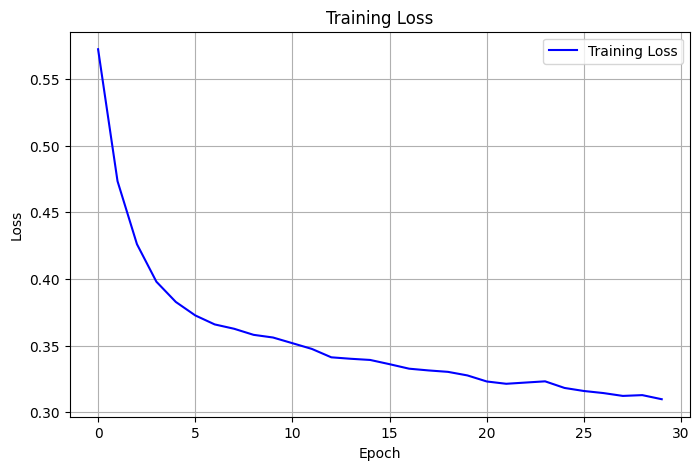

In [31]:
plt.figure(figsize=(8,5))

plt.plot(loss_history, label="Training Loss", color="blue")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.legend()
plt.grid(True)

plt.show()

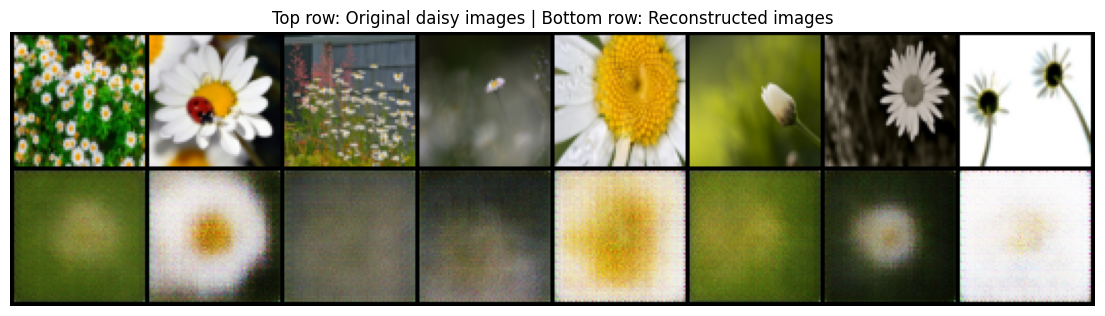

In [32]:
model.eval()

with torch.no_grad():
    test_images = next(iter(train_loader))[:8].to(device)
    recon_images, _, _ = model(test_images)

# Show originals on the first row and reconstructions on the second row
comparison = torch.cat([test_images.cpu(), recon_images.cpu()], dim=0)
comparison = denormalize(comparison).clamp(0, 1)
grid = make_grid(comparison, nrow=8)

plt.figure(figsize=(14, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Top row: Original daisy images | Bottom row: Reconstructed images")
plt.show()

## 14. Generating New Images

Fully random latent vectors often produce noisy images in this small model.  
A better student-level approach is:

1. take real flower images,
2. encode them into latent vectors,
3. add a small amount of Gaussian noise,
4. decode the changed latent vectors.

This still demonstrates generation because the output is not just a direct reconstruction, but it stays close to the learned flower image space.

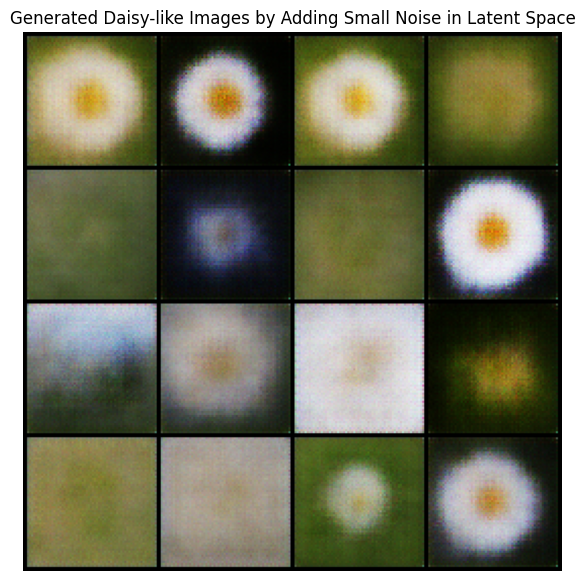

In [33]:
model.eval()

num_samples = 16
noise_strength = 0.25

with torch.no_grad():
    real_images = next(iter(train_loader))[:num_samples].to(device)

    # Encode real images into the latent space
    mu, logvar = model.encode(real_images)

    # Add small Gaussian noise instead of sampling from a totally random latent vector
    z = mu + noise_strength * torch.randn_like(mu)

    generated = model.decode(z).cpu()

grid = make_grid(denormalize(generated).clamp(0, 1), nrow=4)

plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Generated Daisy-like Images by Adding Small Noise in Latent Space")
plt.show()

## 15. Why the Results Are Still Not Perfect

The generated images should look more flower-like than using completely random latent vectors, but they may still be somewhat blurry.

This is expected because:

- the model is intentionally lightweight,
- the images are only 64×64,
- the dataset subset is small,
- training is limited to Colab-friendly time,
- this is a simple ViT autoencoder, not a large diffusion model or GAN.

So the goal here is not photorealistic flower generation.  
The main goal is to clearly demonstrate how ViT-style patch embeddings and transformer encoder layers can be used inside an image generation project.

## References

Dosovitskiy, A., Beyer, L., Kolesnikov, A., Weissenborn, D., Zhai, X., Unterthiner, T., Dehghani, M., Minderer, M., Heigold, G., Gelly, S., Uszkoreit, J., & Houlsby, N. (2021). *An image is worth 16x16 words: Transformers for image recognition at scale*. International Conference on Learning Representations.

Kingma, D. P., & Welling, M. (2014). *Auto-encoding variational Bayes*. International Conference on Learning Representations.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, N., Kaiser, Ł., & Polosukhin, I. (2017). *Attention is all you need*. Advances in Neural Information Processing Systems, 30.

Mamaev, A. (2018). *Flowers Recognition* [Data set]. Kaggle. https://www.kaggle.com/datasets/alxmamaev/flowers-recognition